# 16 · Model reduction and realisation theory

A realisation of a transfer function is a state-space model with that input-output behaviour; the minimal
one has as many states as the system's order, and a *balanced* one orders those states by how much each
contributes to the input-output map, measured by the Hankel singular values. This notebook computes
controllability and observability Gramians, balances a model, reduces it by truncation with the error bound
that comes with it, reconstructs a model from impulse-response data by the eigensystem realisation algorithm
(Ho-Kalman), and shows how the same singular values decide the order of a model fitted to data.

**What you will learn**
- compute Gramians and Hankel singular values and interpret them
- balance a realisation and truncate it with the error bound
- realise a model from impulse-response data (ERA)
- explain why balanced or modal coordinates are numerically preferable

**Before you start:** notebooks 00 and 08  ·  **Time:** about 60 min

In [1]:
try:                      # on Google Colab (or anywhere englincontrol is missing): install it from GitHub
    import englincontrol
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/englincontrol"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from englincontrol import systems as sy, linalg as la, identify as idf, response as rs, frequency as fr, polynomials as pl, discrete as dc, models
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## Gramians: what the input reaches and what the output sees

In [2]:
mot = models.dc_motor()["system"]
Wc, Wo = la.gramians(mot.A, mot.B, mot.C)
print("controllability Gramian Wc =\n", np.round(Wc, 6), "\nobservability Gramian Wo =\n", np.round(Wo, 6))
print("eigenvalues of Wc Wo (invariant under similarity):", np.round(np.sort(np.linalg.eigvals(Wc @ Wo).real), 8))
bal, hsv = sy.balanced_realisation(mot)
Wcb, Wob = la.gramians(bal.A, bal.B, bal.C)
print("balanced: both Gramians diagonal and equal to diag(Hankel singular values):", np.round(np.diag(Wcb), 6), np.round(np.diag(Wob), 6), "| HSV", np.round(hsv, 6))

controllability Gramian Wc =
 [[0.999167 0.08325 ]
 [0.08325  0.008325]] 
observability Gramian Wo =
 [[0.002081 0.004163]
 [0.004163 0.049992]]
eigenvalues of Wc Wo (invariant under similarity): [3.81900e-05 3.15057e-03]
balanced: both Gramians diagonal and equal to diag(Hankel singular values): [0.05613 0.00618] [0.05613 0.00618] | HSV [0.05613 0.00618]


The controllability Gramian W_c = ∫e^{At}BBᵀe^{Aᵀt}dt measures how much energy an input can put into each
state direction; the observability Gramian W_o measures how much each state direction shows in the output.
Each depends on the coordinates, but the eigenvalues of their product do not: their square roots, the Hankel
singular values, are the system's own numbers. In balanced coordinates both Gramians equal diag(σ₁, σ₂, …),
and a state with a small σ is both hard to excite and hard to see - a candidate for removal.

## Balanced truncation and its error bound

Hankel singular values of a 6th-order model: [1.49492e+00 1.27930e-01 2.03400e-02 2.59000e-03 6.10000e-04 3.20000e-04]


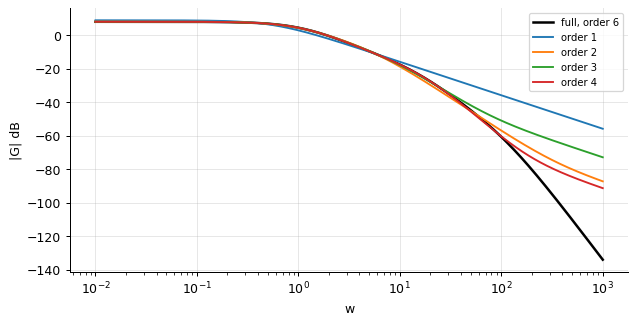

 kept states  max |G - G_r|  bound 2 sum(discarded HSV)  within bound
           1       2.77e-01                    3.04e-01          True
           2       3.20e-02                    4.77e-02          True
           3       5.06e-03                    7.05e-03          True
           4       5.57e-04                    1.87e-03          True


In [3]:
big = sy.zpk([-3.0, -30.0], [-1.0, -2.0, -15.0, -20.0, -100.0, -120.0], 2e5).to_ss()
bal, hsv = sy.balanced_realisation(big)
print("Hankel singular values of a 6th-order model:", np.round(hsv, 5))
w = np.logspace(-2, 3, 500)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.semilogx(w, 20 * np.log10(np.abs(fr.freqresp(big, w))), "k", lw=2, label="full, order 6")
rows = []
for k in (1, 2, 3, 4):
    red = idf.balanced_truncation(big, k)
    err = np.max(np.abs(fr.freqresp(big, w) - fr.freqresp(red["system"], w)))
    rows.append((k, err, red["error_bound"], err <= red["error_bound"]))
    ax.semilogx(w, 20 * np.log10(np.abs(fr.freqresp(red["system"], w))), label=f"order {k}")
ax.legend(fontsize=8); ax.set_xlabel("w"); ax.set_ylabel("|G| dB"); plt.show()
print(pd.DataFrame(rows, columns=["kept states", "max |G - G_r|", "bound 2 sum(discarded HSV)", "within bound"]).to_string(index=False, float_format="%.2e"))

Truncating the balanced realisation to its k largest singular values gives a stable reduced model whose
H∞ error is at most twice the sum of the discarded singular values (Glover 1984, Enns 1984) - a guarantee
before any response is computed, which a frequency sweep confirms. Two states capture this sixth-order model
to a few percent across the band; the fast modes at 100 rad/s contribute almost nothing to the input-output
map and are the first to go.

## Realisation from data: Ho-Kalman / ERA

In [4]:
Gd = dc.c2d(mot, 0.01)
t, ys = rs.step(Gd, 1.0)
markov = np.r_[ys[0], np.diff(ys)]                                # the impulse response = the Markov parameters h_0, h_1, ...
rng = np.random.default_rng(0)
for noise in (0.0, 1e-4):
    e = idf.era(markov + noise * rng.normal(size=len(markov)), 2, 0.01)
    print(f"noise {noise}: ERA poles {np.round(np.sort(e['system'].poles().real), 5)} (true {np.round(np.sort(Gd.poles().real), 5)}); first Hankel singular values {np.round(e['hankel_singular_values'][:5], 5)}")

noise 0.0: ERA poles [0.90486 0.98017] (true [0.90486 0.98017]); first Hankel singular values [0.04693 0.0055  0.      0.      0.     ]
noise 0.0001: ERA poles [0.89674 0.98059] (true [0.90486 0.98017]); first Hankel singular values [0.04669 0.00574 0.00127 0.00121 0.00118]


From the Markov parameters (the impulse response) the block Hankel matrix has rank equal to the system order,
and its SVD yields a realisation directly: the eigensystem realisation algorithm. Without noise the third
singular value is zero and the poles are exact; with a little noise the singular values beyond the order
become small but nonzero, and reading the order off the gap is the practitioner's judgement. ERA is the
ancestor of the subspace identification methods, and the Hankel matrix is the bridge between realisation
theory and identification.

## Why representations matter numerically

In [5]:
rows = []
for n in (4, 8, 12):
    poles = -np.arange(1, n + 1, dtype=float)
    G = sy.zpk([], poles, 1.0)
    S_c = G.to_ss()                                                # controllable canonical
    S_b, _ = sy.balanced_realisation(S_c)
    rows.append((n, np.linalg.cond(S_c.A), np.linalg.cond(S_b.A), np.max(np.abs(np.sort(S_c.poles().real) - np.sort(poles))), np.max(np.abs(np.sort(S_b.poles().real) - np.sort(poles)))))
print(pd.DataFrame(rows, columns=["order", "cond(A) canonical", "cond(A) balanced", "pole error canonical", "pole error balanced"]).to_string(index=False, float_format="%.2e"))

 order  cond(A) canonical  cond(A) balanced  pole error canonical  pole error balanced
     4           1.83e+02          1.20e+01              3.86e-14             6.22e-15
     8           8.10e+05          3.78e+01              8.47e-12             7.45e-09
    12           1.80e+10          3.31e+02              5.62e-08             7.93e-04


The table does not say what one expects. The companion matrix of a 12th-order polynomial has a condition
number of 10¹⁰ against a few hundred for the balanced realisation - and yet its poles come out *more*
accurately (10⁻⁸ against 10⁻³). Two things are at work. The conditioning of a matrix is not the conditioning
of its eigenvalues, and the QR algorithm (with its own internal balancing) handles companion matrices well.
And the balanced realisation was *computed*, from the companion form through two Gramians and a
transformation containing the inverse fourth roots of Hankel singular values that span ten orders of
magnitude; the transformation is itself ill-conditioned and injects the error. A representation is only as
good as the arithmetic that produced it - notebook 18 pushes the order to where both routes fail. Transfer-function coefficients are a convenient notation and a poor numerical representation; the
library converts to state space for every computation that matters and keeps balanced or modal forms when it
can (notebook 18 continues the theme).

## Inside the algorithm: balancing by the Cholesky-SVD route

In [6]:
Wc_, Wo_ = la.gramians(mot.A, mot.B, mot.C)
Lc = np.linalg.cholesky(Wc_)
U_, s_, Vt_ = np.linalg.svd(Lc.T @ Wo_ @ Lc)
T_ = Lc @ U_ @ np.diag(s_ ** -0.25)
balanced = mot.transform(T_)
Wcb_, Wob_ = la.gramians(balanced.A, balanced.B, balanced.C)
print("Gramians after the transformation:", np.round(np.diag(Wcb_), 6), np.round(np.diag(Wob_), 6), "- equal and diagonal; HSV = sqrt of the singular values:", np.round(np.sqrt(s_), 6))

Gramians after the transformation: [0.05613 0.00618] [0.05613 0.00618] - equal and diagonal; HSV = sqrt of the singular values: [0.05613 0.00618]


## Exercises
1. Reduce the quarter-car model (4 states, 2 inputs, 2 outputs) to 2 states by balanced truncation and compare the singular-value plots of the full and reduced models; which mode was dropped, and at what frequency does the reduced model fail?
2. Build the Hankel matrix from the motor's noisy impulse response with 10, 30 and 100 Markov parameters and tabulate the first five singular values; how does the gap between the second and third evolve with the record length and the noise?
3. **Implement it yourself:** write the ERA algorithm (block Hankel matrix, SVD, A = S^-1/2 U' H1 V S^-1/2, B and C from the factors) for the DC motor's discrete impulse response and compare the realised transfer function with the ZOH model.